In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

DATASET_PATH = "/content/drive/MyDrive/Scoliosis_Project 1/dataset"

print("Dataset exists:", os.path.exists(DATASET_PATH))
print("\nContents:")

for item in os.listdir(DATASET_PATH):
    print(" -", item)

Dataset exists: True

Contents:
 - train
 - val


In [ ]:
import os

DATASET_PATH = "/content/drive/MyDrive/Scoliosis_Project 1/dataset"

folders = {
    "Train Normal": os.path.join(DATASET_PATH, "train", "normal"),
    "Train Scoliosis": os.path.join(DATASET_PATH, "train", "scoliosis"),
    "Validation Normal": os.path.join(DATASET_PATH, "val", "normal"),
    "Validation Scoliosis": os.path.join(DATASET_PATH, "val", "scoliosis")
}

for name, path in folders.items():
    if os.path.exists(path):
        files = [
            f for f in os.listdir(path)
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
        ]
        print(f"{name}: {len(files)} images")
    else:
        print(f"{name}: ❌ NOT FOUND → {path}")

Train Normal: 57 images
Train Scoliosis: 150 images
Validation Normal: 14 images
Validation Scoliosis: 38 images


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

DATASET_PATH = "/content/drive/MyDrive/Scoliosis_Project 1/dataset"

train_normal_path = os.path.join(DATASET_PATH, "train", "normal")
train_scoliosis_path = os.path.join(DATASET_PATH, "train", "scoliosis")
val_normal_path = os.path.join(DATASET_PATH, "val", "normal")
val_scoliosis_path = os.path.join(DATASET_PATH, "val", "scoliosis")

# Collect image paths
def get_image_paths(folder):
    return [
        os.path.join(folder, f)
        for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ]

train_normal = get_image_paths(train_normal_path)
train_scoliosis = get_image_paths(train_scoliosis_path)
val_normal = get_image_paths(val_normal_path)
val_scoliosis = get_image_paths(val_scoliosis_path)

print("Train Normal:", len(train_normal))
print("Train Scoliosis:", len(train_scoliosis))
print("Val Normal:", len(val_normal))
print("Val Scoliosis:", len(val_scoliosis))


Train Normal: 57
Train Scoliosis: 150
Val Normal: 14
Val Scoliosis: 38


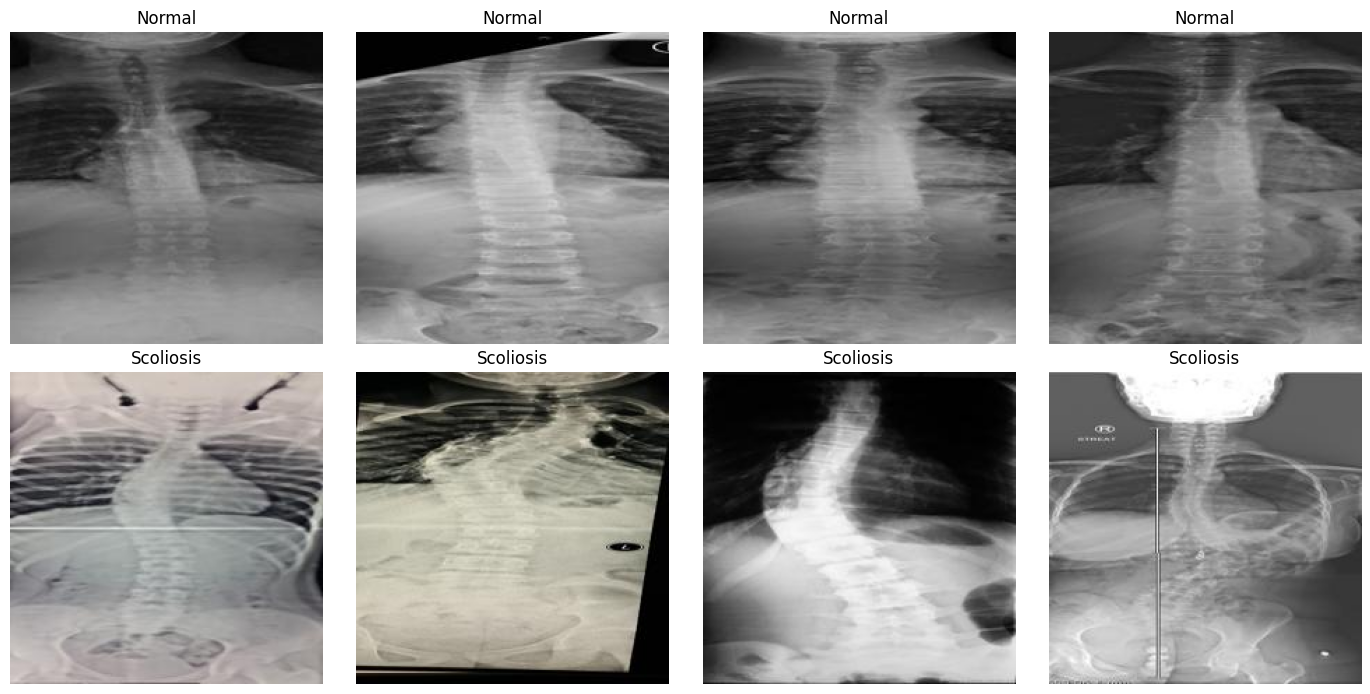

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

samples_normal = np.random.choice(train_normal, 4, replace=False)
samples_scoliosis = np.random.choice(train_scoliosis, 4, replace=False)

for i, path in enumerate(samples_normal):
    img = Image.open(path)
    axes[0, i].imshow(img, cmap="gray")
    axes[0, i].set_title("Normal")
    axes[0, i].axis("off")

for i, path in enumerate(samples_scoliosis):
    img = Image.open(path)
    axes[1, i].imshow(img, cmap="gray")
    axes[1, i].set_title("Scoliosis")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

IMG_SIZE = (224, 224)
BATCH_SIZE = 16

feature_extractor = MobileNetV2(
    weights="imagenet",
    include_top=False,
    pooling="avg",
    input_shape=(224, 224, 3)
)

feature_extractor.trainable = False

feature_extractor.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
import tensorflow as tf
import numpy as np

IMG_SIZE = (224, 224)
BATCH_SIZE = 16

TRAIN_DIR = "/content/drive/MyDrive/Scoliosis_Project 1/dataset/train"
VAL_DIR = "/content/drive/MyDrive/Scoliosis_Project 1/dataset/val"

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    labels="inferred",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    labels="inferred",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Classes:", train_ds.class_names)

Found 207 files belonging to 2 classes.
Found 52 files belonging to 2 classes.
Classes: ['normal', 'scoliosis']


In [ ]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

def preprocess_images(images, labels):
    images = tf.cast(images, tf.float32)
    images = preprocess_input(images)
    return images, labels

train_processed = train_ds.map(
    preprocess_images,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_processed = val_ds.map(
    preprocess_images,
    num_parallel_calls=tf.data.AUTOTUNE
)

In [ ]:
train_features = feature_extractor.predict(
    train_processed,
    verbose=1
)

val_features = feature_extractor.predict(
    val_processed,
    verbose=1
)

print("Train feature shape:", train_features.shape)
print("Validation feature shape:", val_features.shape)

13/13 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step
Train feature shape: (207, 1280)
Validation feature shape: (52, 1280)


In [ ]:
train_labels = np.concatenate([
    labels.numpy().flatten()
    for _, labels in train_ds
])

val_labels = np.concatenate([
    labels.numpy().flatten()
    for _, labels in val_ds
])

print("Train labels:", train_labels.shape)
print("Validation labels:", val_labels.shape)

print("\nTrain distribution:")
print("Normal:", np.sum(train_labels == 0))
print("Scoliosis:", np.sum(train_labels == 1))

print("\nValidation distribution:")
print("Normal:", np.sum(val_labels == 0))
print("Scoliosis:", np.sum(val_labels == 1))

Train labels: (207,)
Validation labels: (52,)

Train distribution:
Normal: 57
Scoliosis: 150

Validation distribution:
Normal: 14
Scoliosis: 38


In [ ]:
print("Train features:", train_features.shape)
print("Validation features:", val_features.shape)

Train features: (207, 1280)
Validation features: (52, 1280)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

train_features_scaled = scaler.fit_transform(train_features)
val_features_scaled = scaler.transform(val_features)

print("Scaled train shape:", train_features_scaled.shape)
print("Scaled validation shape:", val_features_scaled.shape)

Scaled train shape: (207, 1280)
Scaled validation shape: (52, 1280)


In [ ]:
from sklearn.decomposition import PCA
import numpy as np

pca_full = PCA()
train_pca_full = pca_full.fit_transform(train_features_scaled)

cumulative_variance = np.cumsum(
    pca_full.explained_variance_ratio_
)

for n in [2, 4, 8, 16, 32, 64, 128]:
    if n <= len(cumulative_variance):
        print(
            f"{n:3d} components → "
            f"{cumulative_variance[n-1] * 100:.2f}% variance retained"
        )

  2 components → 16.96% variance retained
  4 components → 23.86% variance retained
  8 components → 32.97% variance retained
 16 components → 44.59% variance retained
 32 components → 59.58% variance retained
 64 components → 76.46% variance retained
128 components → 92.68% variance retained


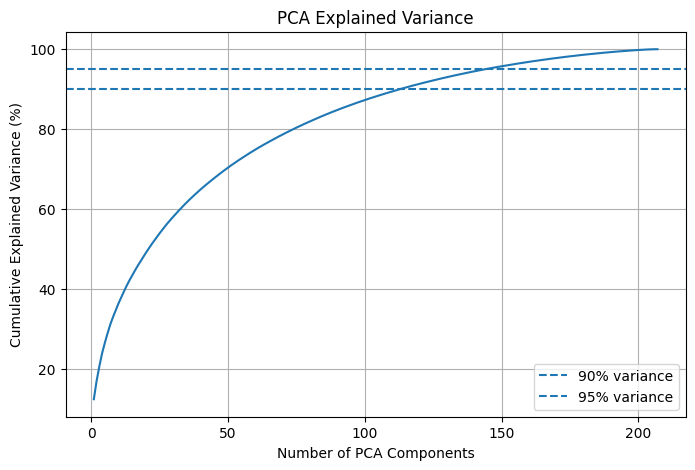

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance * 100
)

plt.axhline(90, linestyle="--", label="90% variance")
plt.axhline(95, linestyle="--", label="95% variance")

plt.xlabel("Number of PCA Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("PCA Explained Variance")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
N_QUBITS = 4

pca = PCA(n_components=N_QUBITS)

train_pca = pca.fit_transform(train_features_scaled)
val_pca = pca.transform(val_features_scaled)

print("Train PCA shape:", train_pca.shape)
print("Validation PCA shape:", val_pca.shape)

print(
    f"\nVariance retained by {N_QUBITS} components: "
    f"{np.sum(pca.explained_variance_ratio_) * 100:.2f}%"
)

Train PCA shape: (207, 4)
Validation PCA shape: (52, 4)

Variance retained by 4 components: 23.86%


In [ ]:
N_QUBITS = 4

pca = PCA(n_components=N_QUBITS)

train_pca = pca.fit_transform(train_features_scaled)
val_pca = pca.transform(val_features_scaled)

print("Train PCA shape:", train_pca.shape)
print("Validation PCA shape:", val_pca.shape)

print(
    f"\nVariance retained by {N_QUBITS} components: "
    f"{np.sum(pca.explained_variance_ratio_) * 100:.2f}%"
)

Train PCA shape: (207, 4)
Validation PCA shape: (52, 4)

Variance retained by 4 components: 23.86%


In [ ]:
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

components_list = [4, 8, 16, 32]

results = []

for n_components in components_list:

    # Fit PCA ONLY on training data
    pca_temp = PCA(n_components=n_components)

    X_train_pca = pca_temp.fit_transform(train_features_scaled)
    X_val_pca = pca_temp.transform(val_features_scaled)

    # Classical baseline classifier
    svm = SVC(
        kernel="rbf",
        class_weight="balanced",
        random_state=42
    )

    svm.fit(X_train_pca, train_labels)

    predictions = svm.predict(X_val_pca)

    accuracy = accuracy_score(val_labels, predictions)
    precision = precision_score(val_labels, predictions, zero_division=0)
    recall = recall_score(val_labels, predictions, zero_division=0)
    f1 = f1_score(val_labels, predictions, zero_division=0)

    variance = np.sum(
        pca_temp.explained_variance_ratio_
    ) * 100

    results.append({
        "PCA Components": n_components,
        "Variance Retained (%)": variance,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

 PCA Components  Variance Retained (%)  Accuracy  Precision   Recall  F1 Score
              4              23.863924  0.903846   0.945946 0.921053  0.933333
              8              32.974102  0.942308   0.948718 0.973684  0.961039
             16              44.587032  0.942308   0.926829 1.000000  0.962025
             32              59.489609  0.903846   0.945946 0.921053  0.933333


In [ ]:
!pip install pennylane -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 37.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 23.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.5/51.5 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 32.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 38.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 40.5 MB/s eta 0:00:00


In [ ]:
import pennylane as qml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("PennyLane version:", qml.__version__)

PennyLane version: 0.45.1


In [ ]:
from sklearn.decomposition import PCA

N_QUBITS = 8

pca8 = PCA(n_components=N_QUBITS)

train_pca8 = pca8.fit_transform(train_features_scaled)
val_pca8 = pca8.transform(val_features_scaled)

print("Train PCA shape:", train_pca8.shape)
print("Validation PCA shape:", val_pca8.shape)

print(
    "Variance retained:",
    pca8.explained_variance_ratio_.sum() * 100,
    "%"
)

Train PCA shape: (207, 8)
Validation PCA shape: (52, 8)
Variance retained: 32.9743 %


In [ ]:
from sklearn.preprocessing import MinMaxScaler

quantum_scaler = MinMaxScaler(feature_range=(-np.pi, np.pi))

X_train_q = quantum_scaler.fit_transform(train_pca8)
X_val_q = quantum_scaler.transform(val_pca8)

print("Quantum train shape:", X_train_q.shape)
print("Quantum validation shape:", X_val_q.shape)

print("\nFirst quantum feature vector:")
print(X_train_q[0])

Quantum train shape: (207, 8)
Quantum validation shape: (52, 8)

First quantum feature vector:
[-2.716758   -1.9839742   0.57322943 -0.17614017 -1.2450397  -0.4233166
 -1.0060792  -0.62484217]


In [ ]:
n_qubits = 8

dev = qml.device(
    "default.qubit",
    wires=n_qubits
)

print(dev)

<default.qubit device (wires=8) at 0x7e055d17aa50>


In [ ]:
n_layers = 2

@qml.qnode(dev)
def quantum_circuit(inputs, weights):

    # Encode classical features
    for i in range(n_qubits):
        qml.RY(inputs[i], wires=i)

    # Variational layers
    for layer in range(n_layers):

        for i in range(n_qubits):
            qml.RY(
                weights[layer, i, 0],
                wires=i
            )

            qml.RZ(
                weights[layer, i, 1],
                wires=i
            )

        # Entanglement
        for i in range(n_qubits - 1):
            qml.CNOT(
                wires=[i, i + 1]
            )

        # Close the ring
        qml.CNOT(
            wires=[n_qubits - 1, 0]
        )

    # Measurement
    return qml.expval(qml.PauliZ(0))

In [ ]:
np.random.seed(42)

weights = np.random.normal(
    0,
    0.1,
    size=(n_layers, n_qubits, 2)
)

print("Weights shape:", weights.shape)

Weights shape: (2, 8, 2)


In [ ]:
# Test the quantum circuit on one training sample

test_output = quantum_circuit(
    X_train_q[0],
    weights
)

print("Quantum circuit output:", test_output)
print("Output type:", type(test_output))

Quantum circuit output: 0.16263159953546824
Output type: <class 'numpy.float64'>


In [ ]:
import pennylane as qml
from pennylane import numpy as pnp

n_qubits = 8
n_layers = 2

dev = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev, interface="autograd")
def quantum_circuit(inputs, weights):

    # Feature encoding
    for i in range(n_qubits):
        qml.RY(inputs[i], wires=i)

    # Variational layers
    for layer in range(n_layers):

        for i in range(n_qubits):
            qml.RY(
                weights[layer, i, 0],
                wires=i
            )

            qml.RZ(
                weights[layer, i, 1],
                wires=i
            )

        # Entanglement
        for i in range(n_qubits - 1):
            qml.CNOT(wires=[i, i + 1])

        # Ring connection
        qml.CNOT(wires=[n_qubits - 1, 0])

    return qml.expval(qml.PauliZ(0))

In [ ]:
X_train_q_pnp = pnp.array(
    X_train_q,
    requires_grad=False
)

y_train_pnp = pnp.array(
    train_labels,
    requires_grad=False
)

X_val_q_pnp = pnp.array(
    X_val_q,
    requires_grad=False
)

y_val_pnp = pnp.array(
    val_labels,
    requires_grad=False
)

weights = pnp.array(
    np.random.normal(
        0,
        0.1,
        size=(n_layers, n_qubits, 2)
    ),
    requires_grad=True
)

print("Training data:", X_train_q_pnp.shape)
print("Training labels:", y_train_pnp.shape)
print("Validation data:", X_val_q_pnp.shape)
print("Validation labels:", y_val_pnp.shape)
print("Weights:", weights.shape)

Training data: (207, 8)
Training labels: (207,)
Validation data: (52, 8)
Validation labels: (52,)
Weights: (2, 8, 2)


In [ ]:
def quantum_probability(x, weights):
    output = quantum_circuit(x, weights)
    return (output + 1.0) / 2.0

In [ ]:
test_probability = quantum_probability(
    X_train_q_pnp[0],
    weights
)

print("Quantum probability:", test_probability)

Quantum probability: 0.6367897049010028


In [ ]:
def binary_cross_entropy(weights, X, y):

    predictions = pnp.stack([
        quantum_probability(x, weights)
        for x in X
    ])

    # Numerical stability
    predictions = pnp.clip(
        predictions,
        1e-7,
        1 - 1e-7
    )

    loss = -pnp.mean(
        y * pnp.log(predictions)
        +
        (1 - y) * pnp.log(1 - predictions)
    )

    return loss

In [ ]:
initial_loss = binary_cross_entropy(
    weights,
    X_train_q_pnp,
    y_train_pnp
)

print("Initial loss:", initial_loss)

Initial loss: 0.7067981399478913


In [ ]:
# Adam optimizer
opt = qml.AdamOptimizer(stepsize=0.05)

epochs = 30

loss_history = []

print("Starting VQC training...\n")

for epoch in range(epochs):

    weights, loss = opt.step_and_cost(
        lambda w: binary_cross_entropy(
            w,
            X_train_q_pnp,
            y_train_pnp
        ),
        weights
    )

    loss_history.append(float(loss))

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(
            f"Epoch {epoch + 1:02d}/{epochs} "
            f"- Loss: {float(loss):.6f}"
        )

Starting VQC training...

Epoch 01/30 - Loss: 0.706798
Epoch 05/30 - Loss: 0.656394
Epoch 10/30 - Loss: 0.615497
Epoch 15/30 - Loss: 0.579520
Epoch 20/30 - Loss: 0.550020
Epoch 25/30 - Loss: 0.537912
Epoch 30/30 - Loss: 0.538838


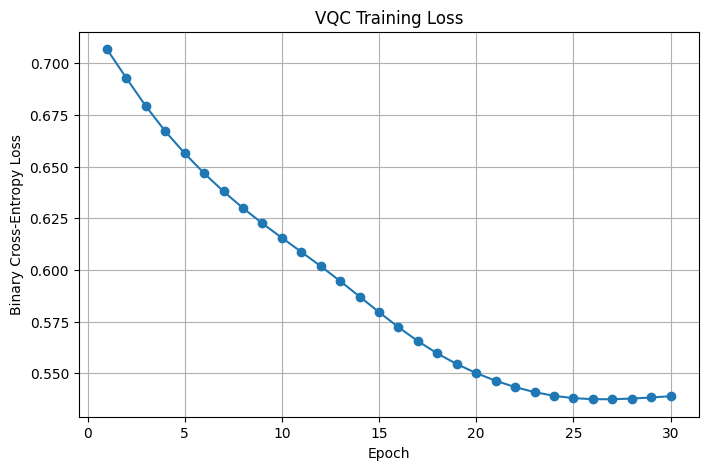

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, epochs + 1),
    loss_history,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("VQC Training Loss")
plt.grid(True)

plt.show()

In [ ]:
val_probabilities = np.array([
    float(
        quantum_probability(
            x,
            weights
        )
    )
    for x in X_val_q_pnp
])

val_predictions = (
    val_probabilities >= 0.5
).astype(int)

print("Validation probabilities:")
print(val_probabilities)

print("\nValidation predictions:")
print(val_predictions)

Validation probabilities:
[0.71246596 0.33152187 0.56776024 0.51661683 0.46785819 0.37485279
 0.30201026 0.46757841 0.3767368  0.35211691 0.47246705 0.43950435
 0.36644773 0.29427712 0.4747397  0.41284265 0.47840712 0.38994366
 0.4843329  0.60995655 0.45148215 0.46863849 0.42502401 0.76066341
 0.55802465 0.45173393 0.60837522 0.3494858  0.59201023 0.50560542
 0.54378271 0.55456401 0.47410933 0.44938872 0.51938095 0.48337414
 0.50390575 0.47845767 0.54397173 0.33236218 0.53853415 0.47275977
 0.39959779 0.7707176  0.48272159 0.47671581 0.3692399  0.65156803
 0.48585094 0.6455752  0.58971221 0.53244803]

Validation predictions:
[1 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 1 0 1 0 1 1 1 1 0 0 1 0 1
 0 1 0 1 0 0 1 0 0 0 1 0 1 1 1]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

accuracy = accuracy_score(
    val_labels,
    val_predictions
)

precision = precision_score(
    val_labels,
    val_predictions,
    zero_division=0
)

recall = recall_score(
    val_labels,
    val_predictions,
    zero_division=0
)

f1 = f1_score(
    val_labels,
    val_predictions,
    zero_division=0
)

print("Hybrid QML VQC Results")
print("=" * 35)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        val_labels,
        val_predictions,
        target_names=["Normal", "Scoliosis"],
        zero_division=0
    )
)

Hybrid QML VQC Results
Accuracy  : 0.5385
Precision : 0.8500
Recall    : 0.4474
F1 Score  : 0.5862

Classification Report:
              precision    recall  f1-score   support

      Normal       0.34      0.79      0.48        14
   Scoliosis       0.85      0.45      0.59        38

    accuracy                           0.54        52
   macro avg       0.60      0.62      0.53        52
weighted avg       0.71      0.54      0.56        52



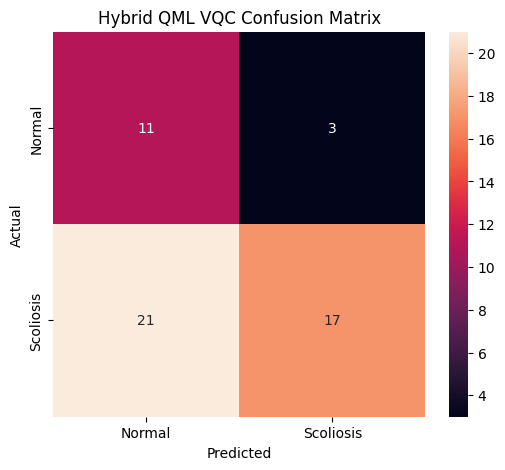

In [ ]:
import seaborn as sns

cm = confusion_matrix(
    val_labels,
    val_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Normal", "Scoliosis"],
    yticklabels=["Normal", "Scoliosis"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Hybrid QML VQC Confusion Matrix")

plt.show()

In [ ]:
n_qubits = 8
n_layers = 3

dev = qml.device(
    "default.qubit",
    wires=n_qubits
)

@qml.qnode(dev, interface="autograd")
def quantum_circuit_v2(inputs, weights):

    for layer in range(n_layers):

        # Data re-uploading
        for i in range(n_qubits):
            qml.RY(
                inputs[i],
                wires=i
            )

            qml.RZ(
                inputs[i],
                wires=i
            )

        # Trainable rotations
        for i in range(n_qubits):
            qml.RY(
                weights[layer, i, 0],
                wires=i
            )

            qml.RZ(
                weights[layer, i, 1],
                wires=i
            )

        # Entanglement
        for i in range(n_qubits - 1):
            qml.CNOT(wires=[i, i + 1])

        # Close the ring
        qml.CNOT(
            wires=[n_qubits - 1, 0]
        )

    return qml.expval(
        qml.PauliZ(0)
    )

print("V2 quantum circuit created.")

V2 quantum circuit created.


In [ ]:
np.random.seed(42)

weights_v2 = pnp.array(
    np.random.normal(
        0,
        0.05,
        size=(n_layers, n_qubits, 2)
    ),
    requires_grad=True
)

print("V2 weights shape:", weights_v2.shape)

V2 weights shape: (3, 8, 2)


In [ ]:
def quantum_probability_v2(x, weights):
    output = quantum_circuit_v2(x, weights)
    return (output + 1.0) / 2.0

In [ ]:
test_probability_v2 = quantum_probability_v2(
    X_train_q_pnp[0],
    weights_v2
)

print("V2 test probability:", test_probability_v2)

V2 test probability: 0.5065095672093389


In [ ]:
normal_weight = len(train_labels) / (
    2 * np.sum(train_labels == 0)
)

scoliosis_weight = len(train_labels) / (
    2 * np.sum(train_labels == 1)
)

print("Normal weight:", normal_weight)
print("Scoliosis weight:", scoliosis_weight)

Normal weight: 1.8157894736842106
Scoliosis weight: 0.69


In [ ]:
def weighted_binary_cross_entropy(
    weights,
    X,
    y
):

    predictions = pnp.stack([
        quantum_probability_v2(
            x,
            weights
        )
        for x in X
    ])

    predictions = pnp.clip(
        predictions,
        1e-7,
        1 - 1e-7
    )

    sample_weights = pnp.where(
        y == 0,
        normal_weight,
        scoliosis_weight
    )

    loss = -pnp.sum(
        sample_weights * (
            y * pnp.log(predictions)
            +
            (1 - y) * pnp.log(1 - predictions)
        )
    ) / pnp.sum(sample_weights)

    return loss

In [ ]:
initial_loss_v2 = weighted_binary_cross_entropy(
    weights_v2,
    X_train_q_pnp,
    y_train_pnp
)

print(
    "Initial V2 loss:",
    float(initial_loss_v2)
)

Initial V2 loss: 0.7021654237138357


In [ ]:
opt = qml.AdamOptimizer(
    stepsize=0.01
)

epochs = 80

loss_history_v2 = []

print("Starting Improved VQC training...\n")

for epoch in range(epochs):

    weights_v2, loss = opt.step_and_cost(
        lambda w: weighted_binary_cross_entropy(
            w,
            X_train_q_pnp,
            y_train_pnp
        ),
        weights_v2
    )

    loss_value = float(loss)

    loss_history_v2.append(
        loss_value
    )

    if (
        (epoch + 1) % 10 == 0
        or epoch == 0
    ):
        print(
            f"Epoch {epoch + 1:03d}/{epochs} "
            f"- Loss: {loss_value:.6f}"
        )

Starting Improved VQC training...

Epoch 001/80 - Loss: 0.702165
Epoch 010/80 - Loss: 0.691663
Epoch 020/80 - Loss: 0.680891
Epoch 030/80 - Loss: 0.673163
Epoch 040/80 - Loss: 0.667053
Epoch 050/80 - Loss: 0.661203
Epoch 060/80 - Loss: 0.655241
Epoch 070/80 - Loss: 0.649927
Epoch 080/80 - Loss: 0.645453


In [ ]:
val_probabilities_v2 = np.array([
    float(
        quantum_probability_v2(
            x,
            weights_v2
        )
    )
    for x in X_val_q_pnp
])

val_predictions_v2 = (
    val_probabilities_v2 >= 0.5
).astype(int)

print("Validation predictions:")
print(val_predictions_v2)

Validation predictions:
[1 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 1 0 0 0 0 0 0 1 1 0 1 1 0
 1 1 1 1 1 0 1 1 0 0 0 1 1 0 0]


In [ ]:
accuracy_v2 = accuracy_score(
    val_labels,
    val_predictions_v2
)

precision_v2 = precision_score(
    val_labels,
    val_predictions_v2,
    zero_division=0
)

recall_v2 = recall_score(
    val_labels,
    val_predictions_v2,
    zero_division=0
)

f1_v2 = f1_score(
    val_labels,
    val_predictions_v2,
    zero_division=0
)

print("Improved Hybrid QML VQC")
print("=" * 35)

print(f"Accuracy  : {accuracy_v2:.4f}")
print(f"Precision : {precision_v2:.4f}")
print(f"Recall    : {recall_v2:.4f}")
print(f"F1 Score  : {f1_v2:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        val_labels,
        val_predictions_v2,
        target_names=[
            "Normal",
            "Scoliosis"
        ],
        zero_division=0
    )
)

Improved Hybrid QML VQC
Accuracy  : 0.5192
Precision : 0.8421
Recall    : 0.4211
F1 Score  : 0.5614

Classification Report:
              precision    recall  f1-score   support

      Normal       0.33      0.79      0.47        14
   Scoliosis       0.84      0.42      0.56        38

    accuracy                           0.52        52
   macro avg       0.59      0.60      0.51        52
weighted avg       0.71      0.52      0.54        52



In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Quantum Kernel SVM setup started.")

Quantum Kernel SVM setup started.


In [ ]:
n_qubits = 8

kernel_dev = qml.device(
    "default.qubit",
    wires=n_qubits
)

@qml.qnode(kernel_dev)
def quantum_feature_map(x):

    # Encode the 8 PCA features
    for i in range(n_qubits):
        qml.Hadamard(wires=i)
        qml.RY(x[i], wires=i)

    # Entanglement
    for i in range(n_qubits - 1):
        qml.CNOT(
            wires=[i, i + 1]
        )

    # Ring connection
    qml.CNOT(
        wires=[n_qubits - 1, 0]
    )

    return qml.state()

In [ ]:
def quantum_kernel(x1, x2):

    state1 = quantum_feature_map(x1)
    state2 = quantum_feature_map(x2)

    overlap = np.vdot(
        state1,
        state2
    )

    return float(
        np.abs(overlap) ** 2
    )

In [ ]:
test_kernel_value = quantum_kernel(
    X_train_q[0],
    X_train_q[1]
)

print(
    "Quantum kernel similarity:",
    test_kernel_value
)

Quantum kernel similarity: 0.1136519416587305


In [ ]:
n_train = len(X_train_q)

K_train = np.zeros(
    (n_train, n_train)
)

print("Computing training quantum kernel matrix...")

for i in range(n_train):

    for j in range(i, n_train):

        value = quantum_kernel(
            X_train_q[i],
            X_train_q[j]
        )

        K_train[i, j] = value
        K_train[j, i] = value

    if (i + 1) % 20 == 0:
        print(
            f"Processed {i + 1}/{n_train}"
        )

print("\nTraining kernel shape:", K_train.shape)

Computing training quantum kernel matrix...
Processed 20/207
Processed 40/207
Processed 60/207
Processed 80/207
Processed 100/207
Processed 120/207
Processed 140/207
Processed 160/207
Processed 180/207
Processed 200/207

Training kernel shape: (207, 207)


In [ ]:
print(
    "First 10 diagonal values:",
    np.diag(K_train)[:10]
)

First 10 diagonal values: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [ ]:
n_val = len(X_val_q)

K_val = np.zeros(
    (n_val, n_train)
)

print("Computing validation quantum kernel matrix...")

for i in range(n_val):

    for j in range(n_train):

        K_val[i, j] = quantum_kernel(
            X_val_q[i],
            X_train_q[j]
        )

    print(
        f"Processed validation sample "
        f"{i + 1}/{n_val}"
    )

print(
    "\nValidation kernel shape:",
    K_val.shape
)

Computing validation quantum kernel matrix...
Processed validation sample 1/52
Processed validation sample 2/52
Processed validation sample 3/52
Processed validation sample 4/52
Processed validation sample 5/52
Processed validation sample 6/52
Processed validation sample 7/52
Processed validation sample 8/52
Processed validation sample 9/52
Processed validation sample 10/52
Processed validation sample 11/52
Processed validation sample 12/52
Processed validation sample 13/52
Processed validation sample 14/52
Processed validation sample 15/52
Processed validation sample 16/52
Processed validation sample 17/52
Processed validation sample 18/52
Processed validation sample 19/52
Processed validation sample 20/52
Processed validation sample 21/52
Processed validation sample 22/52
Processed validation sample 23/52
Processed validation sample 24/52
Processed validation sample 25/52
Processed validation sample 26/52
Processed validation sample 27/52
Processed validation sample 28/52
Processed v

In [ ]:
qsvm = SVC(
    kernel="precomputed",
    class_weight="balanced",
    random_state=42
)

qsvm.fit(
    K_train,
    train_labels
)

print("QSVM training completed.")

QSVM training completed.


In [ ]:
qsvm_predictions = qsvm.predict(
    K_val
)

print("QSVM predictions:")
print(qsvm_predictions)

QSVM predictions:
[1. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1.]


In [ ]:
qsvm_accuracy = accuracy_score(
    val_labels,
    qsvm_predictions
)

qsvm_precision = precision_score(
    val_labels,
    qsvm_predictions,
    zero_division=0
)

qsvm_recall = recall_score(
    val_labels,
    qsvm_predictions,
    zero_division=0
)

qsvm_f1 = f1_score(
    val_labels,
    qsvm_predictions,
    zero_division=0
)

print("Quantum Kernel SVM Results")
print("=" * 35)

print(
    f"Accuracy  : {qsvm_accuracy:.4f}"
)

print(
    f"Precision : {qsvm_precision:.4f}"
)

print(
    f"Recall    : {qsvm_recall:.4f}"
)

print(
    f"F1 Score  : {qsvm_f1:.4f}"
)

print("\nClassification Report:")

print(
    classification_report(
        val_labels,
        qsvm_predictions,
        target_names=[
            "Normal",
            "Scoliosis"
        ],
        zero_division=0
    )
)

Quantum Kernel SVM Results
Accuracy  : 0.9423
Precision : 0.9487
Recall    : 0.9737
F1 Score  : 0.9610

Classification Report:
              precision    recall  f1-score   support

      Normal       0.92      0.86      0.89        14
   Scoliosis       0.95      0.97      0.96        38

    accuracy                           0.94        52
   macro avg       0.94      0.92      0.92        52
weighted avg       0.94      0.94      0.94        52



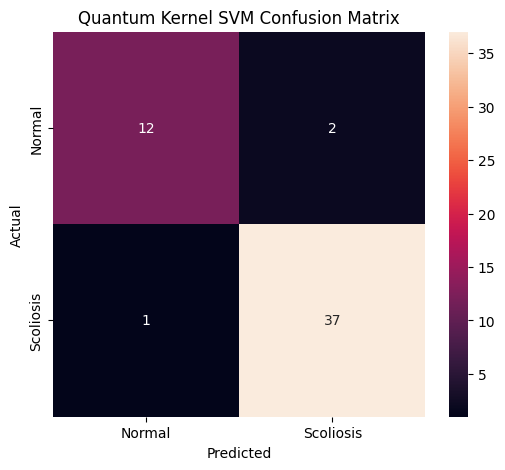

In [ ]:
cm_qsvm = confusion_matrix(
    val_labels,
    qsvm_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_qsvm,
    annot=True,
    fmt="d",
    xticklabels=[
        "Normal",
        "Scoliosis"
    ],
    yticklabels=[
        "Normal",
        "Scoliosis"
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title(
    "Quantum Kernel SVM Confusion Matrix"
)

plt.show()

In [ ]:
print("Kernel shape:", K_train.shape)

print("\nMinimum:", K_train.min())
print("Maximum:", K_train.max())

print("\nDiagonal:")
print(np.diag(K_train)[:10])

Kernel shape: (207, 207)

Minimum: 1.1902930793942972e-14
Maximum: 0.9999999999999989

Diagonal:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [ ]:
eigenvalues = np.linalg.eigvalsh(K_train)

print("Minimum eigenvalue:", eigenvalues.min())
print("Maximum eigenvalue:", eigenvalues.max())

print("\nNumber of significantly negative eigenvalues:",
      np.sum(eigenvalues < -1e-8))

Minimum eigenvalue: 0.0034247206113056337
Maximum eigenvalue: 23.532839776391157

Number of significantly negative eigenvalues: 0


In [ ]:
prediction_agreement = np.mean(
    predictions == qsvm_predictions
)

print(
    "Prediction agreement:",
    prediction_agreement
)

Prediction agreement: 0.9615384615384616


In [ ]:
from sklearn.metrics.pairwise import rbf_kernel

K_classical = rbf_kernel(
    X_train_q,
    X_train_q
)

print("Classical RBF kernel shape:", K_classical.shape)

Classical RBF kernel shape: (207, 207)


In [ ]:
kernel_correlation = np.corrcoef(
    K_train.flatten(),
    K_classical.flatten()
)[0, 1]

print(
    "Quantum vs classical kernel correlation:",
    kernel_correlation
)

Quantum vs classical kernel correlation: 0.8049301373443859


In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score
from sklearn.svm import SVC
import numpy as np

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

quantum_cv_accuracy = []
quantum_cv_f1 = []

classical_cv_accuracy = []
classical_cv_f1 = []

for fold, (train_idx, test_idx) in enumerate(
    skf.split(X_train_q, train_labels),
    start=1
):

    # -----------------------------
    # Quantum Kernel
    # -----------------------------

    K_q_train = K_train[
        np.ix_(train_idx, train_idx)
    ]

    K_q_test = K_train[
        np.ix_(test_idx, train_idx)
    ]

    q_model = SVC(
        kernel="precomputed",
        class_weight="balanced",
        C=1.0,
        random_state=42
    )

    q_model.fit(
        K_q_train,
        train_labels[train_idx]
    )

    q_pred = q_model.predict(
        K_q_test
    )

    q_acc = accuracy_score(
        train_labels[test_idx],
        q_pred
    )

    q_f1 = f1_score(
        train_labels[test_idx],
        q_pred,
        zero_division=0
    )

    quantum_cv_accuracy.append(q_acc)
    quantum_cv_f1.append(q_f1)

    # -----------------------------
    # Classical RBF Kernel
    # -----------------------------

    K_c_train = K_classical[
        np.ix_(train_idx, train_idx)
    ]

    K_c_test = K_classical[
        np.ix_(test_idx, train_idx)
    ]

    c_model = SVC(
        kernel="precomputed",
        class_weight="balanced",
        C=1.0,
        random_state=42
    )

    c_model.fit(
        K_c_train,
        train_labels[train_idx]
    )

    c_pred = c_model.predict(
        K_c_test
    )

    c_acc = accuracy_score(
        train_labels[test_idx],
        c_pred
    )

    c_f1 = f1_score(
        train_labels[test_idx],
        c_pred,
        zero_division=0
    )

    classical_cv_accuracy.append(c_acc)
    classical_cv_f1.append(c_f1)

    print(
        f"Fold {fold}: "
        f"Quantum Acc={q_acc:.4f}, "
        f"Quantum F1={q_f1:.4f} | "
        f"Classical Acc={c_acc:.4f}, "
        f"Classical F1={c_f1:.4f}"
    )

Fold 1: Quantum Acc=0.9048, Quantum F1=0.9355 | Classical Acc=0.9286, Classical F1=0.9508
Fold 2: Quantum Acc=0.9762, Quantum F1=0.9836 | Classical Acc=0.9762, Classical F1=0.9831
Fold 3: Quantum Acc=0.9512, Quantum F1=0.9677 | Classical Acc=0.9268, Classical F1=0.9508
Fold 4: Quantum Acc=0.9512, Quantum F1=0.9677 | Classical Acc=1.0000, Classical F1=1.0000
Fold 5: Quantum Acc=0.9512, Quantum F1=0.9677 | Classical Acc=0.9512, Classical F1=0.9677


In [ ]:
print("\n===== 5-FOLD CROSS-VALIDATION =====")

print(
    f"Quantum Kernel Accuracy: "
    f"{np.mean(quantum_cv_accuracy):.4f} "
    f"± {np.std(quantum_cv_accuracy):.4f}"
)

print(
    f"Quantum Kernel F1: "
    f"{np.mean(quantum_cv_f1):.4f} "
    f"± {np.std(quantum_cv_f1):.4f}"
)

print()

print(
    f"Classical RBF Accuracy: "
    f"{np.mean(classical_cv_accuracy):.4f} "
    f"± {np.std(classical_cv_accuracy):.4f}"
)

print(
    f"Classical RBF F1: "
    f"{np.mean(classical_cv_f1):.4f} "
    f"± {np.std(classical_cv_f1):.4f}"
)


===== 5-FOLD CROSS-VALIDATION =====
Quantum Kernel Accuracy: 0.9469 ± 0.0232
Quantum Kernel F1: 0.9645 ± 0.0157

Classical RBF Accuracy: 0.9566 ± 0.0282
Classical RBF F1: 0.9705 ± 0.0190


In [ ]:
C_values = [0.01, 0.1, 1, 10, 100]

results_C = []

for C_value in C_values:

    fold_acc = []
    fold_f1 = []

    for train_idx, test_idx in skf.split(
        X_train_q,
        train_labels
    ):

        K_train_fold = K_train[
            np.ix_(train_idx, train_idx)
        ]

        K_test_fold = K_train[
            np.ix_(test_idx, train_idx)
        ]

        model = SVC(
            kernel="precomputed",
            C=C_value,
            class_weight="balanced",
            random_state=42
        )

        model.fit(
            K_train_fold,
            train_labels[train_idx]
        )

        pred = model.predict(
            K_test_fold
        )

        fold_acc.append(
            accuracy_score(
                train_labels[test_idx],
                pred
            )
        )

        fold_f1.append(
            f1_score(
                train_labels[test_idx],
                pred,
                zero_division=0
            )
        )

    results_C.append({
        "C": C_value,
        "Accuracy Mean": np.mean(fold_acc),
        "Accuracy Std": np.std(fold_acc),
        "F1 Mean": np.mean(fold_f1),
        "F1 Std": np.std(fold_f1)
    })

results_C_df = pd.DataFrame(results_C)

print(results_C_df.to_string(index=False))

     C  Accuracy Mean  Accuracy Std  F1 Mean   F1 Std
  0.01       0.275261      0.008535 0.000000 0.000000
  0.10       0.922648      0.018151 0.949098 0.011739
  1.00       0.946922      0.023193 0.964463 0.015739
 10.00       0.946922      0.038597 0.964033 0.026260
100.00       0.946922      0.038597 0.964033 0.026260


In [ ]:
best_row = results_C_df.loc[
    results_C_df["F1 Mean"].idxmax()
]

best_C = best_row["C"]

print("Best C based on training 5-fold CV:", best_C)
print(
    "CV Accuracy:",
    best_row["Accuracy Mean"]
)

print(
    "CV F1:",
    best_row["F1 Mean"]
)

Best C based on training 5-fold CV: 1.0
CV Accuracy: 0.9469221835075494
CV F1: 0.9644632469592807


In [ ]:
final_qsvm = SVC(
    kernel="precomputed",
    C=1.0,
    class_weight="balanced",
    random_state=42
)

final_qsvm.fit(
    K_train,
    train_labels
)

print("Final Quantum Kernel SVM trained.")

Final Quantum Kernel SVM trained.


In [ ]:
final_qsvm_predictions = final_qsvm.predict(
    K_val
)

print("Final predictions:")
print(final_qsvm_predictions)

Final predictions:
[1. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1.]


In [ ]:
final_accuracy = accuracy_score(
    val_labels,
    final_qsvm_predictions
)

final_precision = precision_score(
    val_labels,
    final_qsvm_predictions,
    zero_division=0
)

final_recall = recall_score(
    val_labels,
    final_qsvm_predictions,
    zero_division=0
)

final_f1 = f1_score(
    val_labels,
    final_qsvm_predictions,
    zero_division=0
)

print("FINAL QUANTUM KERNEL SVM")
print("=" * 40)

print(f"Accuracy  : {final_accuracy:.4f}")
print(f"Precision : {final_precision:.4f}")
print(f"Recall    : {final_recall:.4f}")
print(f"F1 Score  : {final_f1:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        val_labels,
        final_qsvm_predictions,
        target_names=[
            "Normal",
            "Scoliosis"
        ],
        zero_division=0
    )
)

FINAL QUANTUM KERNEL SVM
Accuracy  : 0.9423
Precision : 0.9487
Recall    : 0.9737
F1 Score  : 0.9610

Classification Report:
              precision    recall  f1-score   support

      Normal       0.92      0.86      0.89        14
   Scoliosis       0.95      0.97      0.96        38

    accuracy                           0.94        52
   macro avg       0.94      0.92      0.92        52
weighted avg       0.94      0.94      0.94        52



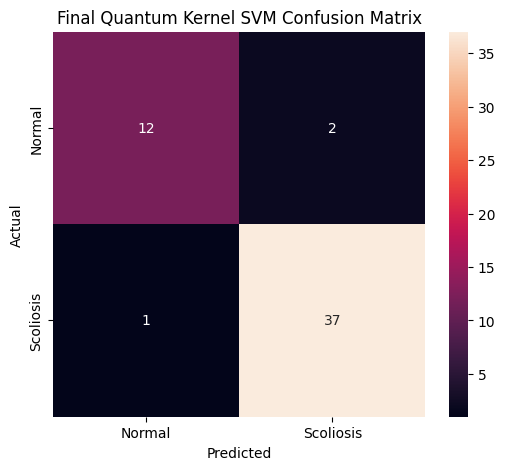

In [ ]:
final_cm = confusion_matrix(
    val_labels,
    final_qsvm_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    final_cm,
    annot=True,
    fmt="d",
    xticklabels=["Normal", "Scoliosis"],
    yticklabels=["Normal", "Scoliosis"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Final Quantum Kernel SVM Confusion Matrix")

plt.show()

In [ ]:
import os

MODEL_DIR = "/content/drive/MyDrive/Scoliosis_Project 1/hybrid_qml_model"

os.makedirs(MODEL_DIR, exist_ok=True)

print("Folder created:")
print(MODEL_DIR)

Folder created:
/content/drive/MyDrive/Scoliosis_Project 1/hybrid_qml_model


In [ ]:
mobilenet_path = os.path.join(
    MODEL_DIR,
    "mobilenetv2_feature_extractor.keras"
)

feature_extractor.save(mobilenet_path)

print("MobileNetV2 saved successfully!")
print(mobilenet_path)


MobileNetV2 saved successfully!
/content/drive/MyDrive/Scoliosis_Project 1/hybrid_qml_model/mobilenetv2_feature_extractor.keras


In [ ]:
import joblib

scaler_path = os.path.join(
    MODEL_DIR,
    "standard_scaler.pkl"
)

joblib.dump(
    scaler,
    scaler_path
)

print("StandardScaler saved successfully!")

StandardScaler saved successfully!


In [ ]:
pca_path = os.path.join(
    MODEL_DIR,
    "pca_8.pkl"
)

joblib.dump(
    pca8,
    pca_path
)

print("PCA-8 saved successfully!")

PCA-8 saved successfully!


In [ ]:
quantum_scaler_path = os.path.join(
    MODEL_DIR,
    "quantum_scaler.pkl"
)

joblib.dump(
    quantum_scaler,
    quantum_scaler_path
)

print("Quantum scaler saved successfully!")

Quantum scaler saved successfully!


In [ ]:
qsvm_path = os.path.join(
    MODEL_DIR,
    "quantum_kernel_svm.pkl"
)

joblib.dump(
    final_qsvm,
    qsvm_path
)

print("Quantum Kernel SVM saved successfully!")

Quantum Kernel SVM saved successfully!


In [ ]:
training_quantum_features_path = os.path.join(
    MODEL_DIR,
    "training_quantum_features.npy"
)

np.save(
    training_quantum_features_path,
    X_train_q
)

print("Training quantum features saved successfully!")

Training quantum features saved successfully!


In [ ]:
print("========== SAVED MODEL FILES ==========")

for filename in os.listdir(MODEL_DIR):
    print(filename)

========== SAVED MODEL FILES ==========
mobilenetv2_feature_extractor.keras
standard_scaler.pkl
pca_8.pkl
quantum_scaler.pkl
quantum_kernel_svm.pkl
training_quantum_features.npy


In [ ]:
import tensorflow as tf
import joblib
import numpy as np

# Load MobileNetV2
loaded_feature_extractor = tf.keras.models.load_model(
    "/content/drive/MyDrive/Scoliosis_Project 1/hybrid_qml_model/mobilenetv2_feature_extractor.keras"
)

# Load StandardScaler
loaded_scaler = joblib.load(
    "/content/drive/MyDrive/Scoliosis_Project 1/hybrid_qml_model/standard_scaler.pkl"
)

# Load PCA
loaded_pca = joblib.load(
    "/content/drive/MyDrive/Scoliosis_Project 1/hybrid_qml_model/pca_8.pkl"
)

# Load Quantum Scaler
loaded_quantum_scaler = joblib.load(
    "/content/drive/MyDrive/Scoliosis_Project 1/hybrid_qml_model/quantum_scaler.pkl"
)

# Load Quantum Kernel SVM
loaded_qsvm = joblib.load(
    "/content/drive/MyDrive/Scoliosis_Project 1/hybrid_qml_model/quantum_kernel_svm.pkl"
)

# Load training quantum features
loaded_training_quantum_features = np.load(
    "/content/drive/MyDrive/Scoliosis_Project 1/hybrid_qml_model/training_quantum_features.npy"
)

print(" All saved model components loaded successfully!")

 All saved model components loaded successfully!


In [ ]:
import os

VAL_DIR = "/content/drive/MyDrive/Scoliosis_Project 1/dataset/val"

# Find the first image
test_image = None

for root, dirs, files in os.walk(VAL_DIR):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
            test_image = os.path.join(root, file)
            break
    if test_image is not None:
        break

print("Test image:")
print(test_image)

Test image:
/content/drive/MyDrive/Scoliosis_Project 1/dataset/val/normal/N57,N,22,F_1_2.jpg


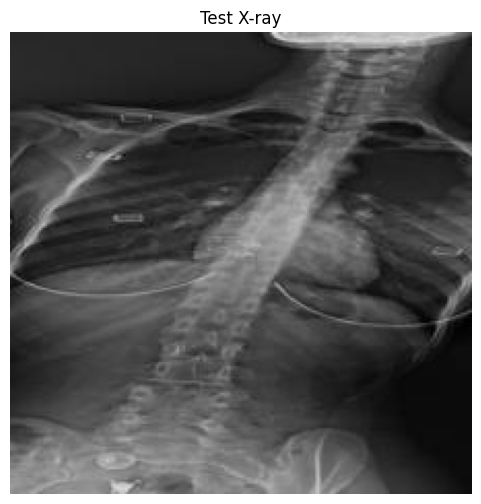

Original image size: (224, 224)


In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open(test_image)

plt.figure(figsize=(6, 6))
plt.imshow(img, cmap="gray")
plt.axis("off")
plt.title("Test X-ray")

plt.show()

print("Original image size:", img.size)

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Load image
img = Image.open(test_image).convert("RGB")

# Resize to MobileNetV2 input size
img_resized = img.resize((224, 224))

# Convert to NumPy array
img_array = np.array(img_resized).astype(np.float32)

# Add batch dimension
img_array = np.expand_dims(img_array, axis=0)

img_array = preprocess_input(img_array)

print("Prepared image shape:", img_array.shape)
print("Data type:", img_array.dtype)

Prepared image shape: (1, 224, 224, 3)
Data type: float32


In [ ]:


test_features = loaded_feature_extractor.predict(
    img_array,
    verbose=0
)

print("Feature shape:", test_features.shape)

Feature shape: (1, 1280)


In [ ]:
# Apply the saved StandardScaler

test_features_scaled = loaded_scaler.transform(test_features)

print("Scaled feature shape:", test_features_scaled.shape)

Scaled feature shape: (1, 1280)


In [ ]:
# Apply the saved PCA model

test_pca8 = loaded_pca.transform(test_features_scaled)

print("PCA feature shape:", test_pca8.shape)
print("8 PCA features:")
print(test_pca8)

PCA feature shape: (1, 8)
8 PCA features:
[[ 6.8923855  6.2516847  6.2241163  3.6874013  8.550564  -0.9262936
  -4.4683704 -5.0224037]]


In [ ]:
# Scale the 8 PCA features for the quantum circuit

test_quantum = loaded_quantum_scaler.transform(test_pca8)

print("Quantum input shape:", test_quantum.shape)
print("Quantum input:")
print(test_quantum)

Quantum input shape: (1, 8)
Quantum input:
[[ 1.0899405  -0.72846645  1.337013    0.22117263  0.8999882  -1.1663506
  -0.7661567  -1.2205415 ]]


In [ ]:
import pennylane as qml
import numpy as np

# Number of qubits used during training
n_qubits = 8

# Create quantum simulator
deployment_dev = qml.device("default.qubit", wires=n_qubits)

# Same quantum feature map used during training
@qml.qnode(deployment_dev)
def deployment_quantum_feature_map(x):
    for i in range(n_qubits):
        qml.Hadamard(wires=i)
        qml.RY(x[i], wires=i)

    # Chain entanglement
    for i in range(n_qubits - 1):
        qml.CNOT(wires=[i, i + 1])

    # Ring connection
    qml.CNOT(wires=[n_qubits - 1, 0])

    return qml.state()


# Quantum kernel
def deployment_quantum_kernel(x1, x2):
    state1 = deployment_quantum_feature_map(x1)
    state2 = deployment_quantum_feature_map(x2)

    overlap = np.vdot(state1, state2)

    return float(np.abs(overlap) ** 2)

print("Quantum kernel is ready.")

Quantum kernel is ready.


In [ ]:
# Get the single 8-feature quantum input
test_x = test_quantum[0]

# Calculate quantum kernel similarity
test_kernel_values = np.array([
    deployment_quantum_kernel(test_x, train_x)
    for train_x in loaded_training_quantum_features
])

# Reshape for the precomputed SVM
test_kernel_matrix = test_kernel_values.reshape(1, -1)

print("Quantum kernel matrix shape:", test_kernel_matrix.shape)
print("Number of training samples compared:", len(test_kernel_values))
print("First 10 kernel values:")
print(test_kernel_values[:10])

Quantum kernel matrix shape: (1, 207)
Number of training samples compared: 207
First 10 kernel values:
[1.03201110e-02 3.13943035e-02 8.49327035e-04 3.97495272e-03
 6.37092780e-03 4.71307759e-05 2.57333525e-03 2.13109437e-04
 8.50075064e-03 1.68896876e-03]


In [ ]:
# Predict using the trained Quantum Kernel SVM

prediction = loaded_qsvm.predict(test_kernel_matrix)

print("Raw prediction:", prediction)

Raw prediction: [1.]


In [ ]:
# Convert prediction into a readable result

if prediction[0] == 1:
    result = "Scoliosis"
else:
    result = "Normal"

print("=" * 40)
print("       SCOLIOSIS DETECTION RESULT")
print("=" * 40)
print(f"Prediction: {result}")
print("=" * 40)

       SCOLIOSIS DETECTION RESULT
Prediction: Scoliosis


In [ ]:
import os

MODEL_DIR = "/content/drive/MyDrive/Scoliosis_Project 1/hybrid_qml_model"

print("Files in model folder:")
for file in os.listdir(MODEL_DIR):
    print(file)

Files in model folder:
mobilenetv2_feature_extractor.keras
standard_scaler.pkl
pca_8.pkl
quantum_scaler.pkl
quantum_kernel_svm.pkl
training_quantum_features.npy


In [ ]:
import shutil

zip_path = shutil.make_archive(
    "/content/hybrid_qml_model",
    "zip",
    MODEL_DIR
)

print("ZIP created:")
print(zip_path)

ZIP created:
/content/hybrid_qml_model.zip


In [ ]:
from google.colab import files

files.download("/content/hybrid_qml_model.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>